# TEMA 7: FILTROS ESPACIALES

## Librerías

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

## Subir Imagen

In [ ]:
# Subir una imagen local
uploaded = files.upload()

# Leer la imagen
image_path = list(uploaded.keys())[0]
original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

Saving cameraman.png to cameraman.png


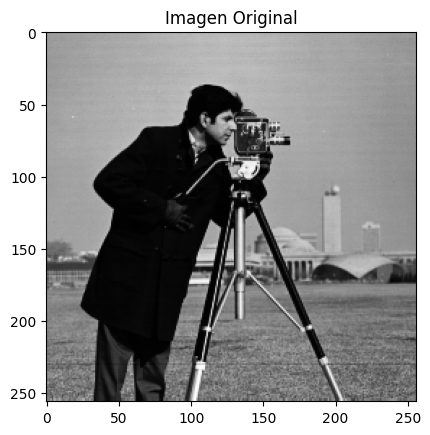

In [ ]:
# Vemos que tiene la imagen
plt.imshow(original_image, cmap='gray')
plt.title('Imagen Original')
plt.axis('on')
plt.show()

## Filtro Paso Bajo
1º Promediado

In [ ]:
np.ones((3, 3), np.int32)

array([[1, 1, 1],
       [1, 1, 1],
       [1, 1, 1]], dtype=int32)

In [ ]:
ventana = 3
kernel = np.ones((ventana, ventana), np.float32) / (ventana * ventana)
print(kernel)
print(f"Cada valor de la matriz vale: 1/{ventana*ventana} = {1/(ventana*ventana)}")

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Cada valor de la matriz vale: 1/9 = 0.1111111111111111


In [ ]:
0.1111111111111111*9

1.0

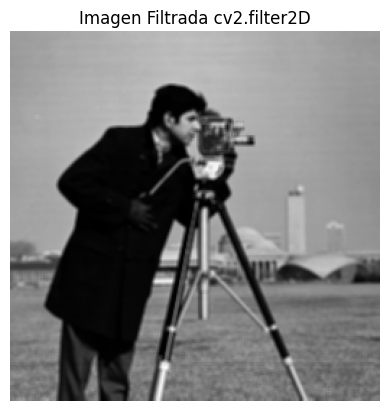

Valor original: 175
Valor filtrado: 176


In [ ]:
# Aplicamos filtro
filtered_image = cv2.filter2D(original_image, -1, kernel)
plt.imshow(filtered_image, cmap='gray')
plt.title('Imagen Filtrada cv2.filter2D')
plt.axis('off')
plt.show()
# pixel 50,50
print(f"Valor original: {original_image[50,50]}")
print(f"Valor filtrado: {filtered_image[50,50]}")

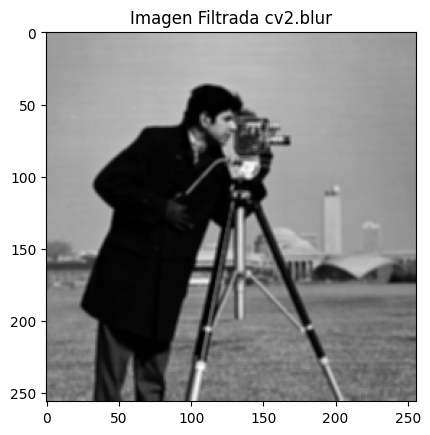

In [ ]:
# Otra forma más rápida
filtered_image2 = cv2.blur(original_image, (ventana, ventana))
plt.imshow(filtered_image2, cmap='gray')
plt.title('Imagen Filtrada cv2.blur')
plt.axis('on')
plt.show()

In [ ]:
# son iguales?
print(f"Son iguales? {np.array_equal(filtered_image, filtered_image2)}")

Son iguales? True


2º Ponderado

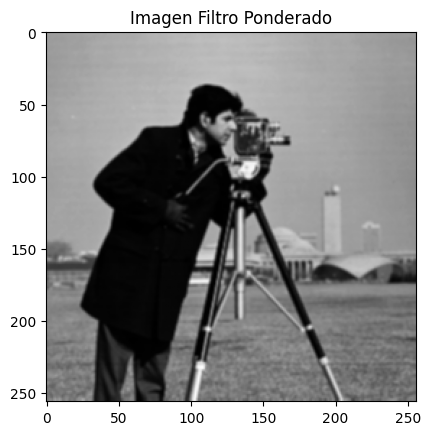

In [ ]:
# Kernel 3x3 ponderado (ejemplo: el centro pesa más)
kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32)

kernel = kernel / kernel.sum()

# aplicamos filtro
filtered_image3 = cv2.filter2D(original_image, -1, kernel)
plt.imshow(filtered_image3, cmap='gray')
plt.title('Imagen Filtro Ponderado')
plt.axis('on')
plt.show()

3º Gaussiano Directo

Para que un filtro ponderado sea gaussiano los pesos deben seguir una distribución normal.

- Todo filtro Gaussiano es un filtro ponderado.

- Pero no todo filtro ponderado es Gaussiano.

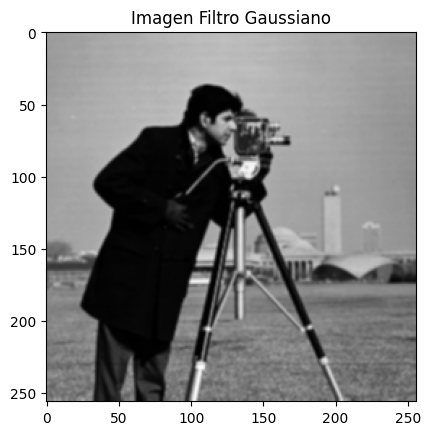

In [ ]:
# Gaussian blur
filetered_image4 = cv2.GaussianBlur(original_image, (ventana, ventana), 0)
plt.imshow(filetered_image4, cmap='gray')
plt.title('Imagen Filtro Gaussiano')
plt.axis('on')
plt.show()

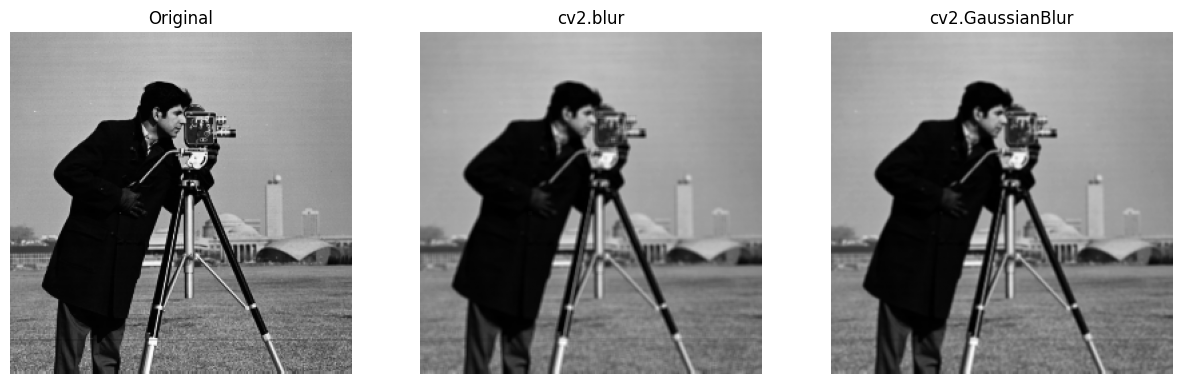

In [ ]:
# Todos juntos
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(filtered_image2, cmap='gray')
plt.title('cv2.blur')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filetered_image4, cmap='gray')
plt.title('cv2.GaussianBlur')
plt.axis('off')
plt.show()

**Nota**

- La función cv2.filter2D en OpenCV maneja los bordes de las imágenes mediante un método de relleno de bordes (padding)

1. `cv2.BORDER_CONSTANT`
  - Rellena los bordes con un valor constante (por defecto, 0, es decir, negro).

2. `cv2.BORDER_REPLICATE`
  - Replica el valor de los píxeles más cercanos al borde.

3. `cv2.BORDER_REFLECT`
  - Refleja los píxeles del borde, pero excluye el último valor del borde.

4. `cv2.BORDER_REFLECT_101` o `cv2.BORDER_DEFAULT`
  - Similar a `BORDER_REFLECT`, pero excluye tanto el primer como el último valor reflejado.

5. Valor por defecto:
  - Si no se especifica un `borderType`, OpenCV utiliza **`cv2.BORDER_DEFAULT`**, equivalente a **`cv2.BORDER_REFLECT_101`**.

  https://wikidocs.net/231809


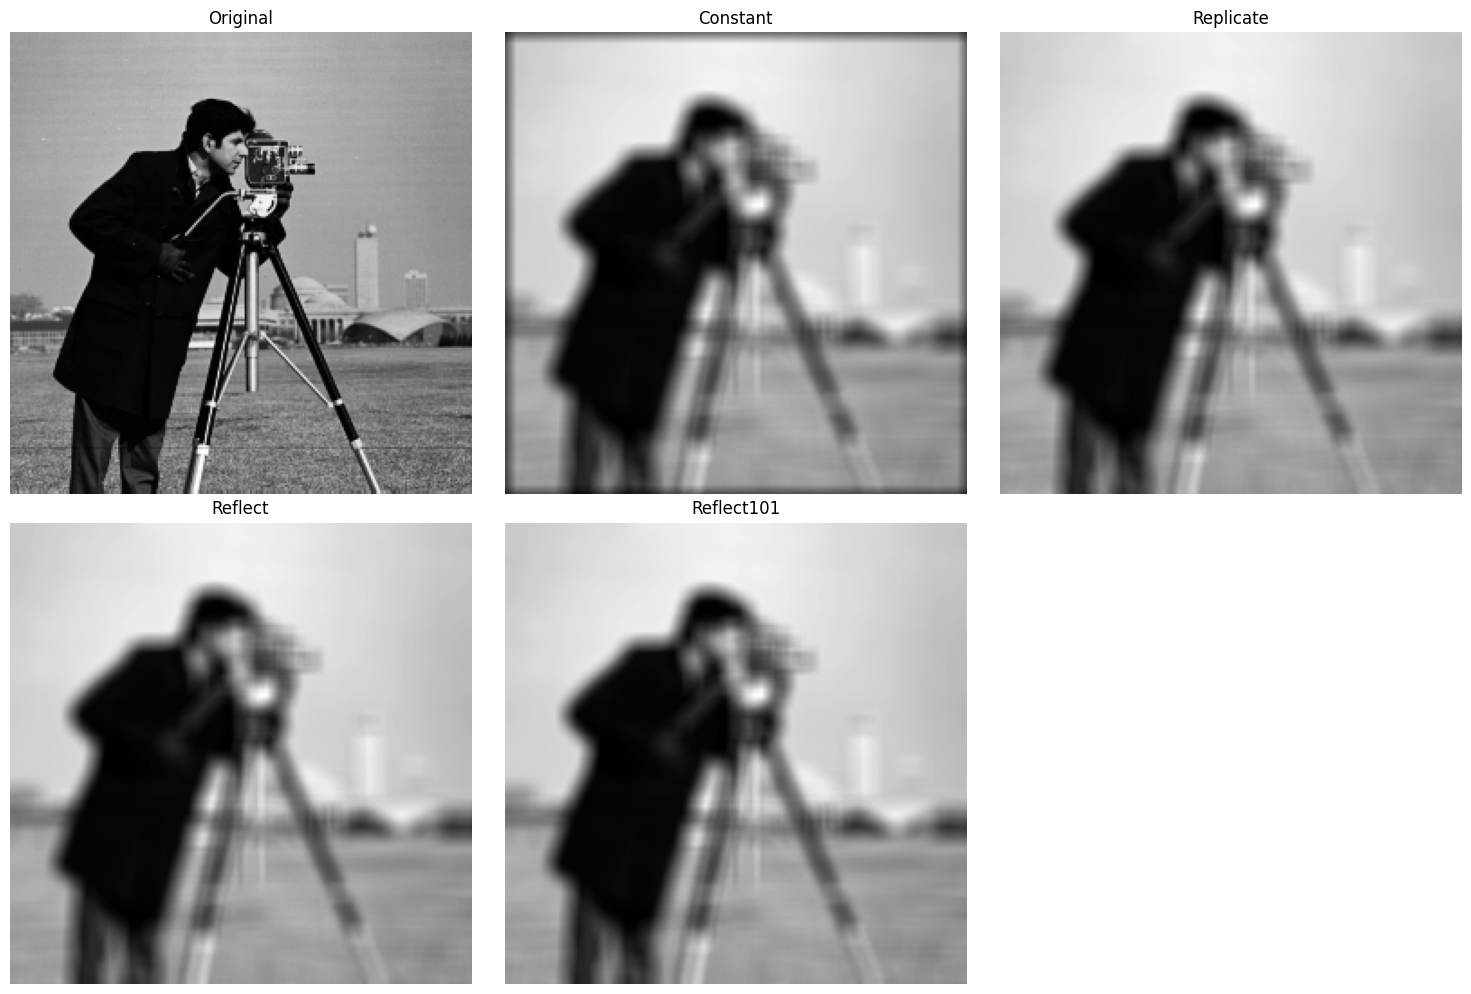

In [ ]:
# Crear un kernel (Box Filter)
kernel_ = np.ones((12, 12), dtype=np.float32) / 144

# Aplicar filtro con diferentes tipos de bordes
constant = cv2.filter2D(original_image, -1, kernel_, borderType=cv2.BORDER_CONSTANT)
replicate = cv2.filter2D(original_image, -1, kernel_, borderType=cv2.BORDER_REPLICATE)
reflect = cv2.filter2D(original_image, -1, kernel_, borderType=cv2.BORDER_REFLECT)
reflect101 = cv2.filter2D(original_image, -1, kernel_, borderType=cv2.BORDER_REFLECT_101)

# Mostrar resultados
titles = ['Original', 'Constant', 'Replicate', 'Reflect', 'Reflect101']
images = [original_image, constant, replicate, reflect, reflect101]

plt.figure(figsize=(15, 10))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.title(titles[i])
    plt.imshow(images[i], cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

## Filtro Paso Alto
### 1º Operador Gradiente X

Saving descarga.png to descarga.png


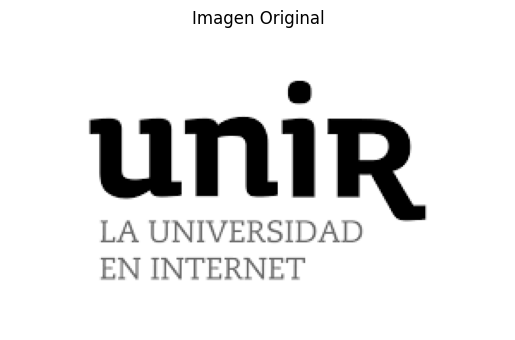

In [ ]:
# Subir una imagen local
uploaded = files.upload()
# Leer la imagen
image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.imshow(image, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')
plt.show()

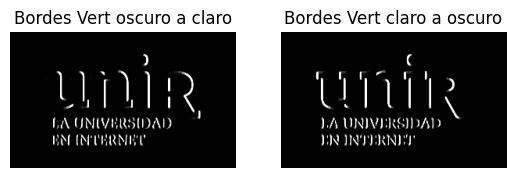

In [ ]:
# Filtro (Bordes Vert trans oscuro a claro)
kernel1 = np.array([
    [-1,  0,  1],
    [-1,  0,  1],
    [-1,  0,  1]
])

# Filtro (Bordes Vert trans claro a oscuro)
kernel2 = np.array([
    [ 1,  0, -1],
    [ 1,  0, -1],
    [ 1,  0, -1]
])

# Aplicamos el filtro
filtered_image1 = cv2.filter2D(image, -1, kernel1)
filtered_image2 = cv2.filter2D(image, -1, kernel2)

# ploteamos
plt.subplot(1, 2, 1)
plt.imshow(filtered_image1, cmap='gray')
plt.title('Bordes Vert oscuro a claro')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_image2, cmap='gray')
plt.title('Bordes Vert claro a oscuro')
plt.axis('off')
plt.show()

### 2º Operador Gradiente Y

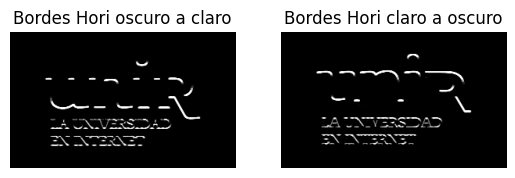

In [ ]:
# Filtro (Bordes Vert trans oscuro a claro)
kernel3 = np.array([
    [-1,  -1,  -1],
    [ 0,   0,   0],
    [ 1,   1,   1]
])

# Filtro (Bordes Vert trans claro a oscuro)
kernel4 = np.array([
    [ 1,   1,  1],
    [ 0,   0,  0],
    [ -1, -1, -1]
])

# Aplicamos el filtro
filtered_image3 = cv2.filter2D(image, -1, kernel3)
filtered_image4 = cv2.filter2D(image, -1, kernel4)

# ploteamos
plt.subplot(1, 2, 1)
plt.imshow(filtered_image3, cmap='gray')
plt.title('Bordes Hori oscuro a claro')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(filtered_image4, cmap='gray')
plt.title('Bordes Hori claro a oscuro')
plt.axis('off')
plt.show()

### 3º Operador Sobel

Saving molinillo.png to molinillo.png


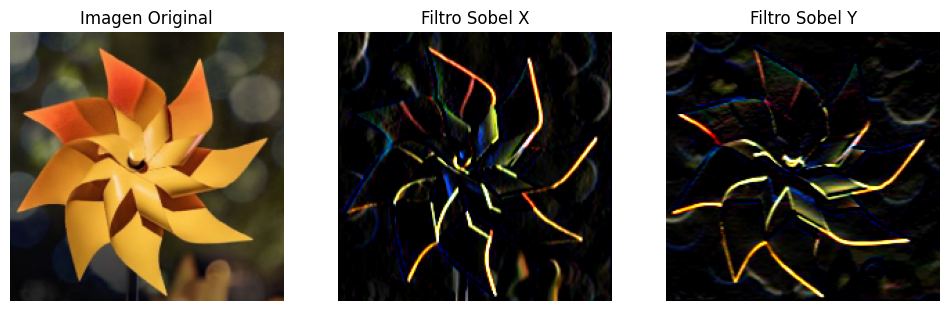

In [ ]:
# Subir una imagen local
uploaded = files.upload()
# Leer la imagen
image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# Definir los filtros paso-alto (kernels) de la diapositiva
kernels = {
    "Filtro Sobel X": np.array([[1,  0,  -1],
                                [2,  0,  -2],
                                [1,  0,  -1]]),

    "Filtro Sobel Y": np.array([[ 1,    2,   1],
                                [ 0,    0,   0],
                                [ -1,  -2,  -1]]),

}

# Aplicar los filtros a la imagen y guardar los resultados
filtered_images = {}
for name, kernel in kernels.items():
    filtered_images[name] = cv2.filter2D(image, ddepth=-1, kernel=kernel)

# Mostrar la imagen original y las imágenes filtradas
plt.figure(figsize=(12, 8))

# Imagen original
plt.subplot(1, 3, 1)
plt.title("Imagen Original", fontsize=12)
plt.imshow(image)
plt.axis('off')

for i, (name, filtered_image) in enumerate(filtered_images.items(), start=2):
  # Updated lista with enough elements to avoid IndexError
  plt.subplot(1, 3,i)
  plt.title(name, fontsize=12)
  plt.imshow(filtered_image)
  plt.axis('off')

### 4º Bordes Diagonales

Saving bordes_diagonales.png to bordes_diagonales.png


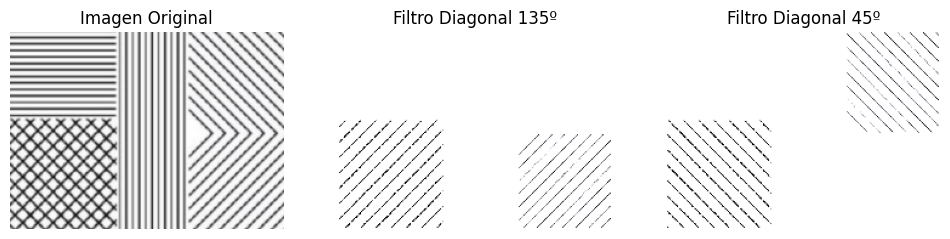

In [ ]:
# Subir una imagen local
uploaded = files.upload()
# Leer la imagen
image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
# Definir los filtros paso-alto (kernels) de la diapositiva
c = 4
kernels = {
    "Filtro Diagonal 135º": np.array([[-1, -1,   c],
                                      [-1,  c,  -1],
                                      [ c, -1,  -1]]),

    "Filtro Diagonal 45º": np.array([[  c, -1,  -1],
                                     [ -1,  c,  -1],
                                     [ -1, -1,  c]]),

}

# Aplicar los filtros a la imagen y guardar los resultados
filtered_images = {}
for name, kernel in kernels.items():
    filtered_images[name] = cv2.filter2D(image, ddepth=-1, kernel=kernel)

# Mostrar la imagen original y las imágenes filtradas
plt.figure(figsize=(12, 8))

# Imagen original
plt.subplot(1, 3, 1)
plt.title("Imagen Original", fontsize=12)
plt.imshow(image)
plt.axis('off')

for i, (name, filtered_image) in enumerate(filtered_images.items(), start=2):
  # Updated lista with enough elements to avoid IndexError
  plt.subplot(1, 3,i)
  plt.title(name, fontsize=12)
  plt.imshow(filtered_image)
  plt.axis('off')

### 5º Operador Laplaciano

Saving cameraman.png to cameraman.png


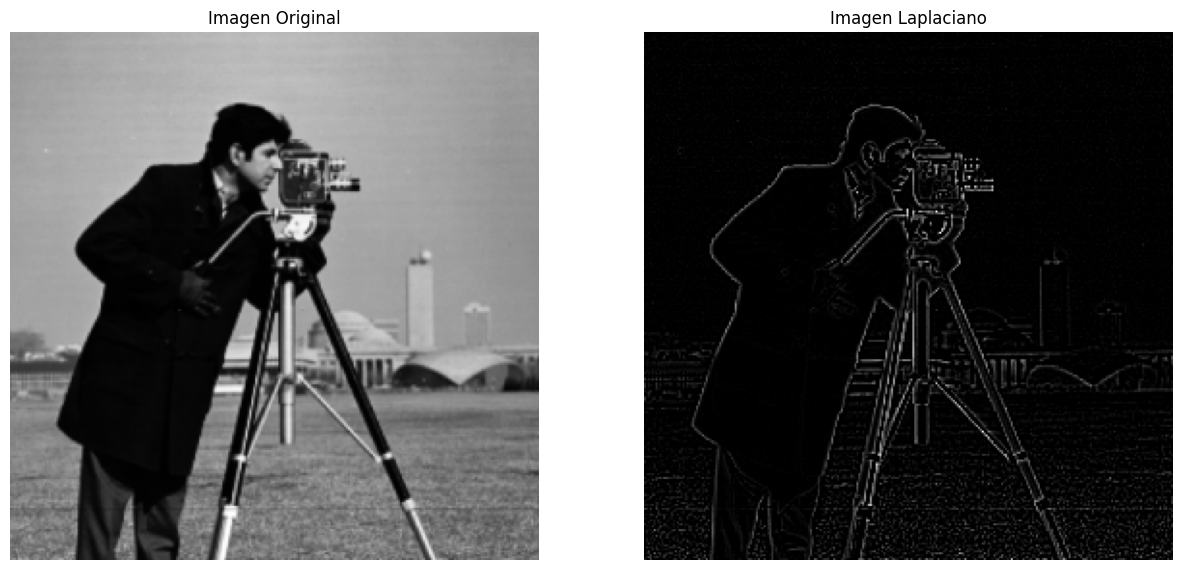

In [4]:
# Subir una imagen local
uploaded = files.upload()
# Leer la imagen
image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

kernel_lap = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

# kernel_lap = np.array([[ -1, -1,  -1],
#                        [ -1,  8,  -1],
#                        [ -1, -1,  -1]])

lap = cv2.filter2D(image, -1, kernel_lap)

plt.figure(figsize=(15, 10))
plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lap, cmap='gray')
plt.title('Imagen Laplaciano')
plt.axis('off')
plt.show()

(np.float64(-0.5), np.float64(273.5), np.float64(273.5), np.float64(-0.5))

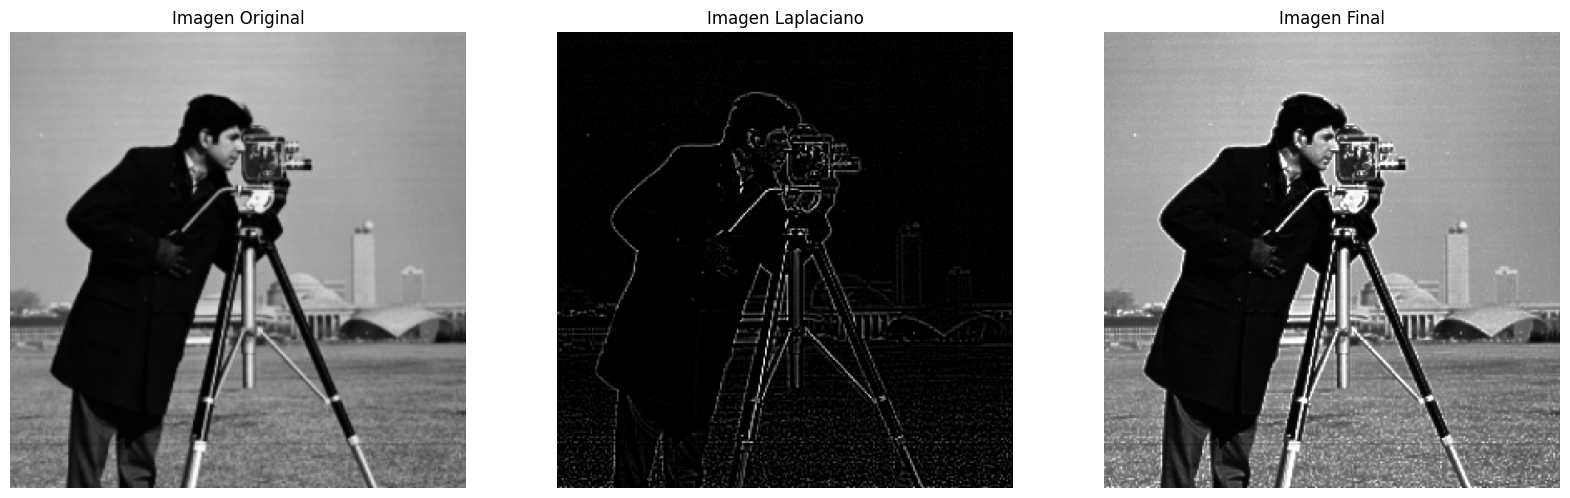

In [7]:
# Subir una imagen local
#uploaded = files.upload()
# Leer la imagen
image_path = list(uploaded.keys())[0]
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
# image = cv2.blur(image, (3, 3))
# Definir los filtros paso-alto (kernels) de la diapositiva
#kernel = np.array([[ 0, -1,  0],
#                   [-1,  4, -1],
#                   [ 0, -1,  0]])

kernel_lap = np.array([[ -1, -1,  -1],
                        [ -1,  8,  -1],
                        [ -1, -1,  -1]])
# Aplicar Laplaciano
laplacian = cv2.filter2D(image, ddepth=-1, kernel=kernel)

# Realce de detalles
lambda_factor = 0.8  # Ajustar según necesidad
enhanced_img = cv2.convertScaleAbs(image + lambda_factor * laplacian)

plt.figure(figsize=(20, 15))
# Imagen original
plt.subplot(1, 3, 1)
plt.title("Imagen Original", fontsize=12)
plt.imshow(image, cmap='gray')
plt.axis('off')

# Imagen Laplaciano
plt.subplot(1, 3, 2)
plt.title("Imagen Laplaciano", fontsize=12)
plt.imshow(laplacian, cmap='gray')
plt.axis('off')

# Imagen Final
plt.subplot(1, 3, 3)
plt.title("Imagen Final", fontsize=12)
plt.imshow(enhanced_img, cmap='gray')
plt.axis('off')

### Operador Roberts

Saving molinillo.png to molinillo.png


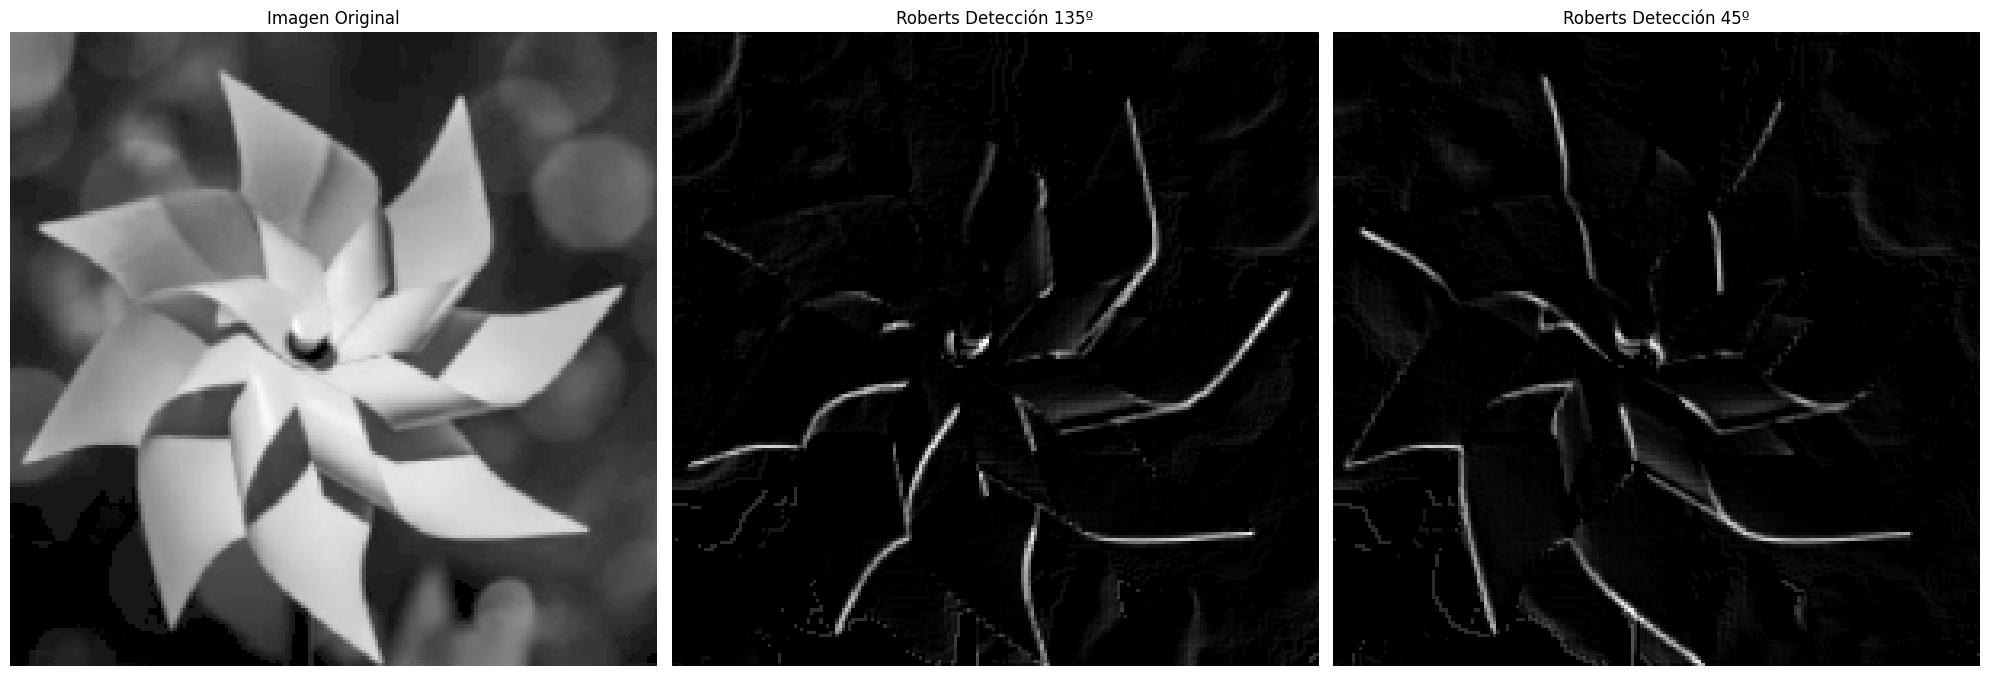

In [8]:
# Subir una imagen local
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Leer la imagen en escala de grises
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Definir los filtros Roberts (kernels)
kernel_roberts_135 = np.array([[1,  0],
                               [0, -1]])
kernel_roberts_45 = np.array([[0,  1],
                              [-1, 0]])

# Aplicar filtros Roberts
roberts_135 = cv2.filter2D(image, ddepth=-1, kernel=kernel_roberts_135)
roberts_45 = cv2.filter2D(image, ddepth=-1, kernel=kernel_roberts_45)

# Magnitud del gradiente (combinación de ambos)
roberts_gradient = cv2.convertScaleAbs(roberts_135 + roberts_45)

# Graficar los resultados
plt.figure(figsize=(20, 10))

# Imagen original
plt.subplot(1, 3, 1)
plt.title("Imagen Original", fontsize=12)
plt.imshow(image, cmap='gray')
plt.axis('off')

# Imagen con gradiente Roberts en X
plt.subplot(1, 3, 2)
plt.title("Roberts Detección 135º", fontsize=12)
plt.imshow(roberts_135, cmap='gray')
plt.axis('off')

# Imagen con gradiente combinado (detector de bordes)
plt.subplot(1, 3, 3)
plt.title("Roberts Detección 45º", fontsize=12)
plt.imshow(roberts_45, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

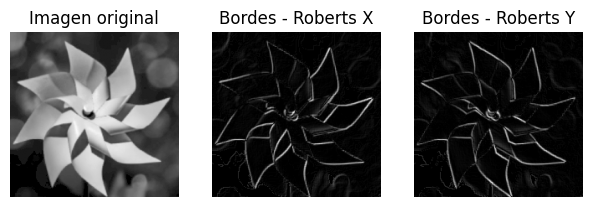

In [9]:
# Normalizar la imagen a rango 0-255 si es necesario
image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX)

# Definir los kernels del operador de Roberts
kernel_x = np.array([[1,  0],
                     [0, -1]], dtype=np.float32)

kernel_y = np.array([[0,  1],
                     [-1, 0]], dtype=np.float32)

# Aplicar los filtros de Roberts
roberts_x = cv2.filter2D(image, cv2.CV_64F, kernel_x)
roberts_y = cv2.filter2D(image, cv2.CV_64F, kernel_y)

# Mostrar los resultados
plt.figure(figsize=(10, 8))

plt.subplot(1, 4, 1)
plt.title("Imagen original")
plt.imshow(image, cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("Bordes - Roberts X")
plt.imshow(np.abs(roberts_x), cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("Bordes - Roberts Y")
plt.imshow(np.abs(roberts_y), cmap='gray')
plt.axis("off")

plt.show()

### Operador Prewitt

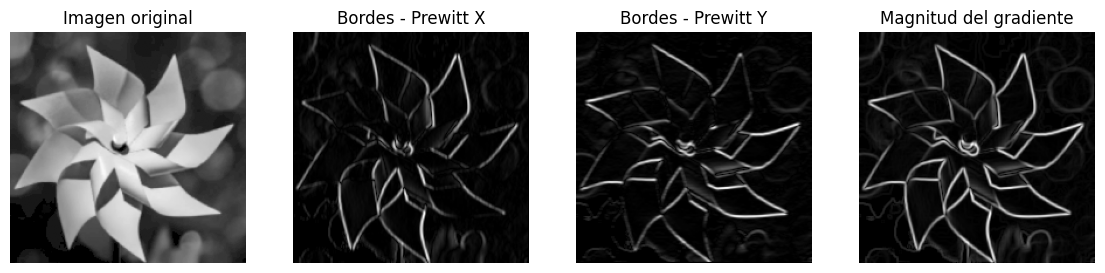

In [10]:
# Normalizar la imagen a rango 0-255 si es necesario
image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX)

# Definir los kernels del operador de Prewitt
kernel_x = np.array([[-1, 0, 1],
                     [-1, 0, 1],
                     [-1, 0, 1]], dtype=np.float32)

kernel_y = np.array([[ 1,  1,  1],
                     [ 0,  0,  0],
                     [-1, -1, -1]], dtype=np.float32)

# Aplicar los filtros de Prewitt
prewitt_x = cv2.filter2D(image, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(image, cv2.CV_64F, kernel_y)

# Calcular la magnitud del gradiente
magnitude = np.sqrt(prewitt_x ** 2 + prewitt_y ** 2)
magnitude = np.uint8(magnitude / magnitude.max() * 255)  # Escalar a rango 0-255

# Mostrar los resultados
plt.figure(figsize=(14, 8))

plt.subplot(1, 4, 1)
plt.title("Imagen original")
plt.imshow(image, cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("Bordes - Prewitt X")
plt.imshow(np.abs(prewitt_x), cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("Bordes - Prewitt Y")
plt.imshow(np.abs(prewitt_y), cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("Magnitud del gradiente")
plt.imshow(magnitude, cmap='gray')
plt.axis("off")

plt.show()

### Operador Sobel

[[ 0  0  0 ...  4  4  0]
 [ 4  4  5 ...  3  6  4]
 [ 0  0  1 ...  0  4  0]
 ...
 [ 6  6  4 ... 40 12  0]
 [ 0  0  6 ... 42 35 35]
 [ 0  0  6 ... 24  0  0]]


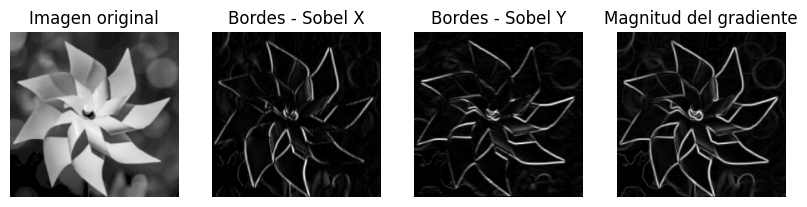

In [12]:
# Normalizar la imagen a rango 0-255 si es necesario
image = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX)

# Aplicar los filtros Sobel para las direcciones X y Y
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)  # Gradiente en X
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)  # Gradiente en Y

# Calcular la magnitud del gradiente
magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
magnitude = np.uint8(magnitude / magnitude.max() * 255)  # Escalar a rango 0-255
print(magnitude)

# Mostrar los resultados
plt.figure(figsize=(10, 8))

plt.subplot(1, 4, 1)
plt.title("Imagen original")
plt.imshow(image, cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("Bordes - Sobel X")
plt.imshow(np.abs(sobel_x), cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("Bordes - Sobel Y")
plt.imshow(np.abs(sobel_y), cmap='gray')
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("Magnitud del gradiente")
plt.imshow(magnitude, cmap='gray')
plt.axis("off")

plt.show()

### Canny

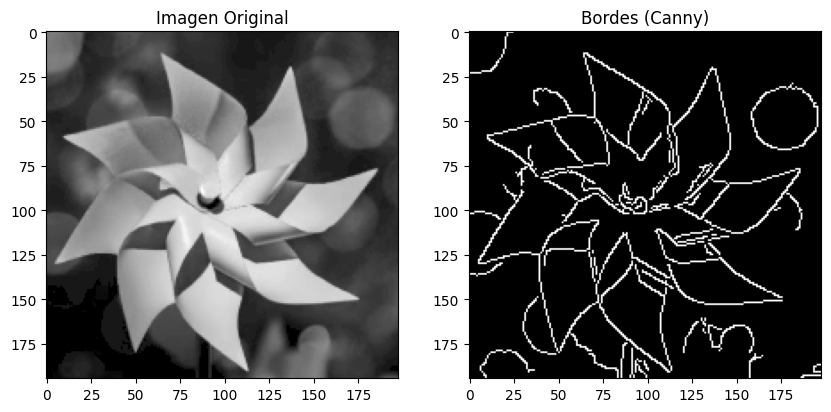

In [ ]:
# Aplicar el detector Canny
low_threshold = 50
high_threshold = 150
edges = cv2.Canny(image, low_threshold, high_threshold)

# Mostrar resultados
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.title("Imagen Original"), plt.imshow(image, cmap='gray')
plt.subplot(1, 2, 2), plt.title("Bordes (Canny)"), plt.imshow(edges, cmap='gray')
plt.show()

Saving coins.png to coins.png


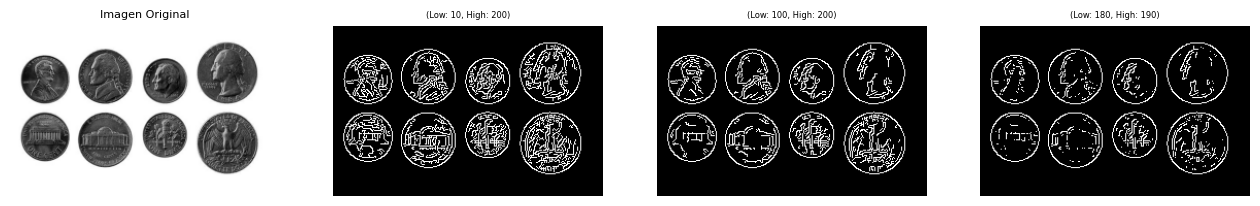

In [13]:
# Cargar la imagen
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Leer la imagen en escala de grises
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Configuraciones de umbrales
thresholds = [
    {"low": 10, "high": 200, "name": "Extremos Lejanos"},
    {"low": 100, "high": 200, "name": "Intermedios"},
    {"low": 180, "high": 190, "name": "Umbrales Cercanos"}
]
# Mostrar la imagen original y las imágenes filtradas
plt.figure(figsize=(16, 8))

# Imagen original
plt.subplot(1, 4, 1)
plt.title("Imagen Original", fontsize=8)
plt.imshow(image, cmap='gray')
plt.axis('off')

# Aplicar Canny para cada configuración de umbrales
for i, config in enumerate(thresholds):
  low_threshold = config["low"]
  high_threshold = config["high"]
  name = config["name"]
  edges = cv2.Canny(image, low_threshold, high_threshold)

  plt.subplot(1, 4, i+2)
  plt.title(f"(Low: {low_threshold}, High: {high_threshold})", fontsize=6)
  plt.imshow(edges, cmap='gray')
  plt.axis('off')

Saving coins.jpg to coins (1).jpg


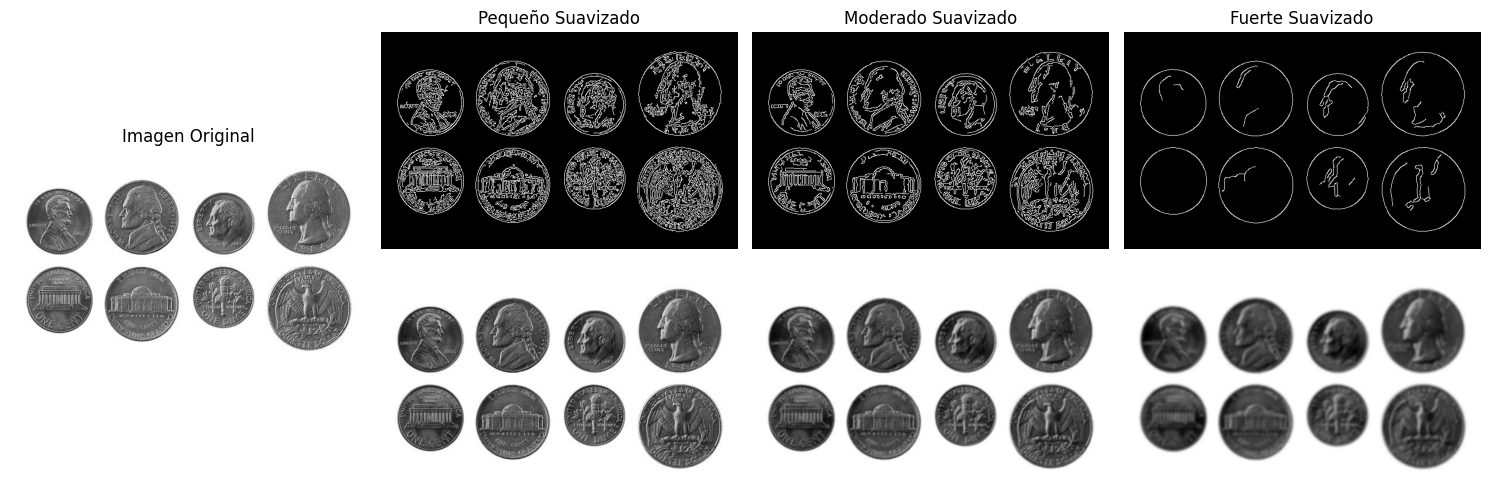

In [ ]:
# Cargar la imagen
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Leer la imagen en escala de grises
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Configuración del filtro Gaussiano y umbrales
gaussian_configs = [
    {"ksize": (3, 3), "sigma": 0.5, "name": "Pequeño Suavizado"},
    {"ksize": (5, 5), "sigma": 1.0, "name": "Moderado Suavizado"},
    {"ksize": (9, 9), "sigma": 2.0, "name": "Fuerte Suavizado"}
]

low_threshold = 50
high_threshold = 150

# Mostrar la imagen original
plt.figure(figsize=(15, 5))
plt.subplot(1, len(gaussian_configs) + 1, 1)
plt.title("Imagen Original")
plt.imshow(image, cmap='gray')
plt.axis('off')

# Aplicar el filtro Gaussiano y Canny para cada configuración
for i, config in enumerate(gaussian_configs):
    # Aplicar filtro Gaussiano
    blurred = cv2.GaussianBlur(image, config["ksize"], config["sigma"])

    # Aplicar el detector de bordes Canny
    edges = cv2.Canny(blurred, low_threshold, high_threshold)

    # Mostrar los resultados
    plt.subplot(2, len(gaussian_configs) + 1, i + 2)
    plt.title(config["name"])
    plt.imshow(edges, cmap='gray')
    plt.axis('off')
    # Mostrar los resultados
    plt.subplot(2, len(gaussian_configs) + 1, 4+(i + 2))
    plt.imshow(blurred, cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()

Saving coins.jpg to coins (2).jpg
He encontrado 9 objetos


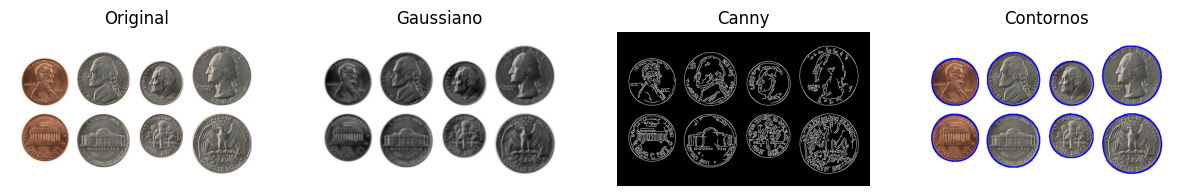

In [ ]:
# Cargar la imagen
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Cargamos la imagen
original = cv2.imread(image_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
# Mostrar la imagen
plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.title("Original")
plt.imshow(original, cmap='gray')
plt.axis('off')

# Convertimos a escala de grises
gris = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

# Aplicar suavizado Gaussiano
gauss = cv2.GaussianBlur(gris, (5,5), 0)

# Mostrar la imagen
plt.subplot(1, 4, 2)
plt.title("Gaussiano")
plt.imshow(gauss, cmap='gray')
plt.axis('off')

# Detectamos los bordes con Canny
canny = cv2.Canny(gauss, 50, 150)

# Mostrar la imagen
plt.subplot(1, 4, 3)
plt.title("Canny")
plt.imshow(canny, cmap='gray')
plt.axis('off')

# Buscamos los contornos
# cv2.RETR_EXTERNAL: Recupera solo los contornos externos de cada objeto.
# cv2.CHAIN_APPROX_SIMPLE: Comprime los puntos del contorno guardando solo los puntos esenciales (menos puntos, ahorra memoria)
(contornos,_) = cv2.findContours(canny.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Mostramos el número de monedas por consola
print("He encontrado {} objetos".format(len(contornos)))

# -1: Indica que se dibujarán todos los contornos encontrados (Si fuese otro número, por ejemplo 0, se dibujaría solo el primer contorno detectado.)
# (0,0,255): Color de los contornos dibujados (en este caso rojo en formato BGR)
# 2: Grosor del contorno dibujado (2 píxeles)
cv2.drawContours(original,contornos,-1,(0,0,255), 2)
# Mostrar la imagen
plt.subplot(1, 4, 4)
plt.title("Contornos")
plt.imshow(original, cmap='gray')
plt.axis('off');

Saving dog.png to dog.png


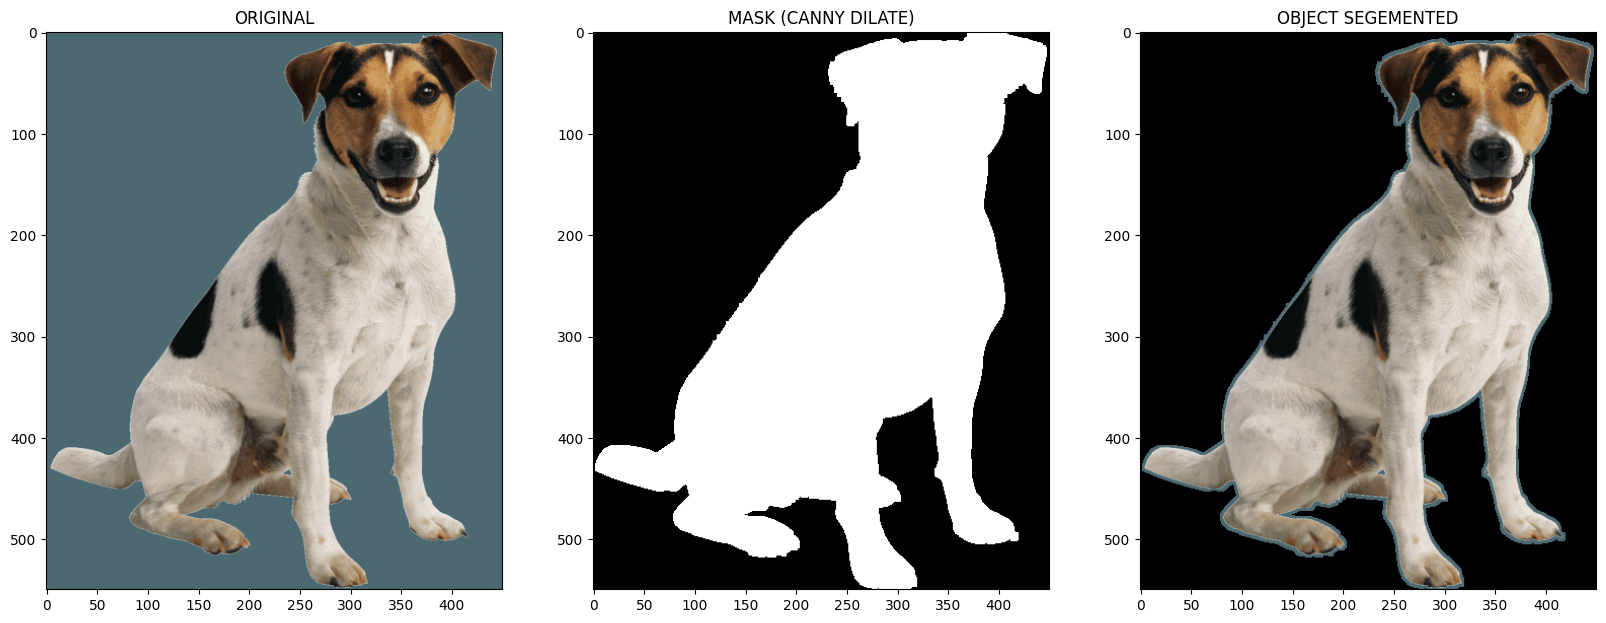

In [14]:
# Cargar la imagen
uploaded = files.upload()
image_path = list(uploaded.keys())[0]
# Cargamos la imagen
img = cv2.imread(image_path)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

canny = cv2.Canny(img_gray, 5,40)
# Ampliamos un poco los bordes del objeto, DILATACIÓN
kernel =np.ones((5,5), np.uint8)
bordes = cv2.dilate(canny, kernel)
# Generamos la máscara
# cv2.RETR_EXTERNAL: Solo contornos externos
# cv2.RETR_LIST: Todos los contornos sin jerarquía
# cv2.RETR_CCOMP: Dos niveles de jerarquía
# cv2.RETR_TREE: Todos los niveles de jerarquía (contornos externos e internos)
contours,_ = cv2.findContours(bordes,  cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
objetos = bordes.copy()
# [max(contours, key=cv2.contourArea)] El contorno más grande de todos los encontrados (área máxima)
cv2.drawContours(objetos, [max(contours, key=cv2.contourArea)],-1,255,thickness=-1)

objetos = objetos/255
seg = np.zeros(img.shape)
seg[:,:,0] = objetos*img[:,:,0]
seg[:,:,1] = objetos*img[:,:,1]
seg[:,:,2] = objetos*img[:,:,2]
seg = np.uint8(seg)

# Comparamos Resultados de ambos
fig, axs = plt.subplots(1,3, figsize=(20, 20))
axs[0].title.set_text('ORIGINAL')
axs[1].title.set_text('MASK (CANNY DILATE)')
axs[2].title.set_text('OBJECT SEGEMENTED')
axs[0].imshow(img);
axs[1].imshow(objetos, cmap='gray');
axs[2].imshow(seg);